## Car Sales Analysis and Sales Prediction

### Exploratory Data Analysis (EDA)

The goal of this notebook is to explore the cleaned dataset and identify patterns and relationships.

#### Objectives

- Understand the distribution of numerical variables
- Analyze categorical variables
- Investigate potential outliers
- Explore relationships between vehicle characteristics and sales
- Identify key factors influencing vehicle sales

### 1. Load Cleaned Data

In [1]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None) #display all columns in a DataFrame without truncation.

df = pd.read_csv("../data/processed/car_sales_clean.csv")

# Restore important data types
df["Latest_Launch"] = pd.to_datetime(df["Latest_Launch"])

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.head()

,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,Acura,Integra,16.919,16.360,Passenger,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2012-02-02,58.280150
1,Acura,TL,39.384,19.875,Passenger,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,2011-06-03,91.370778
2,Acura,CL,14.114,18.225,Passenger,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,2012-01-04,72.030917
3,Acura,RL,8.588,29.725,Passenger,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2011-03-10,91.389779
4,Audi,A4,20.397,22.255,Passenger,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,2011-10-08,62.777639


### 2. Numerical Feature Analysis

Understanding the distribution of numerical variables helps identify patterns and unusual values within the dataset.

In this section, we analyze the distribution of key numerical features, including:

- Sales volume
- Vehicle price
- Engine size
- Horsepower
- Fuel efficiency

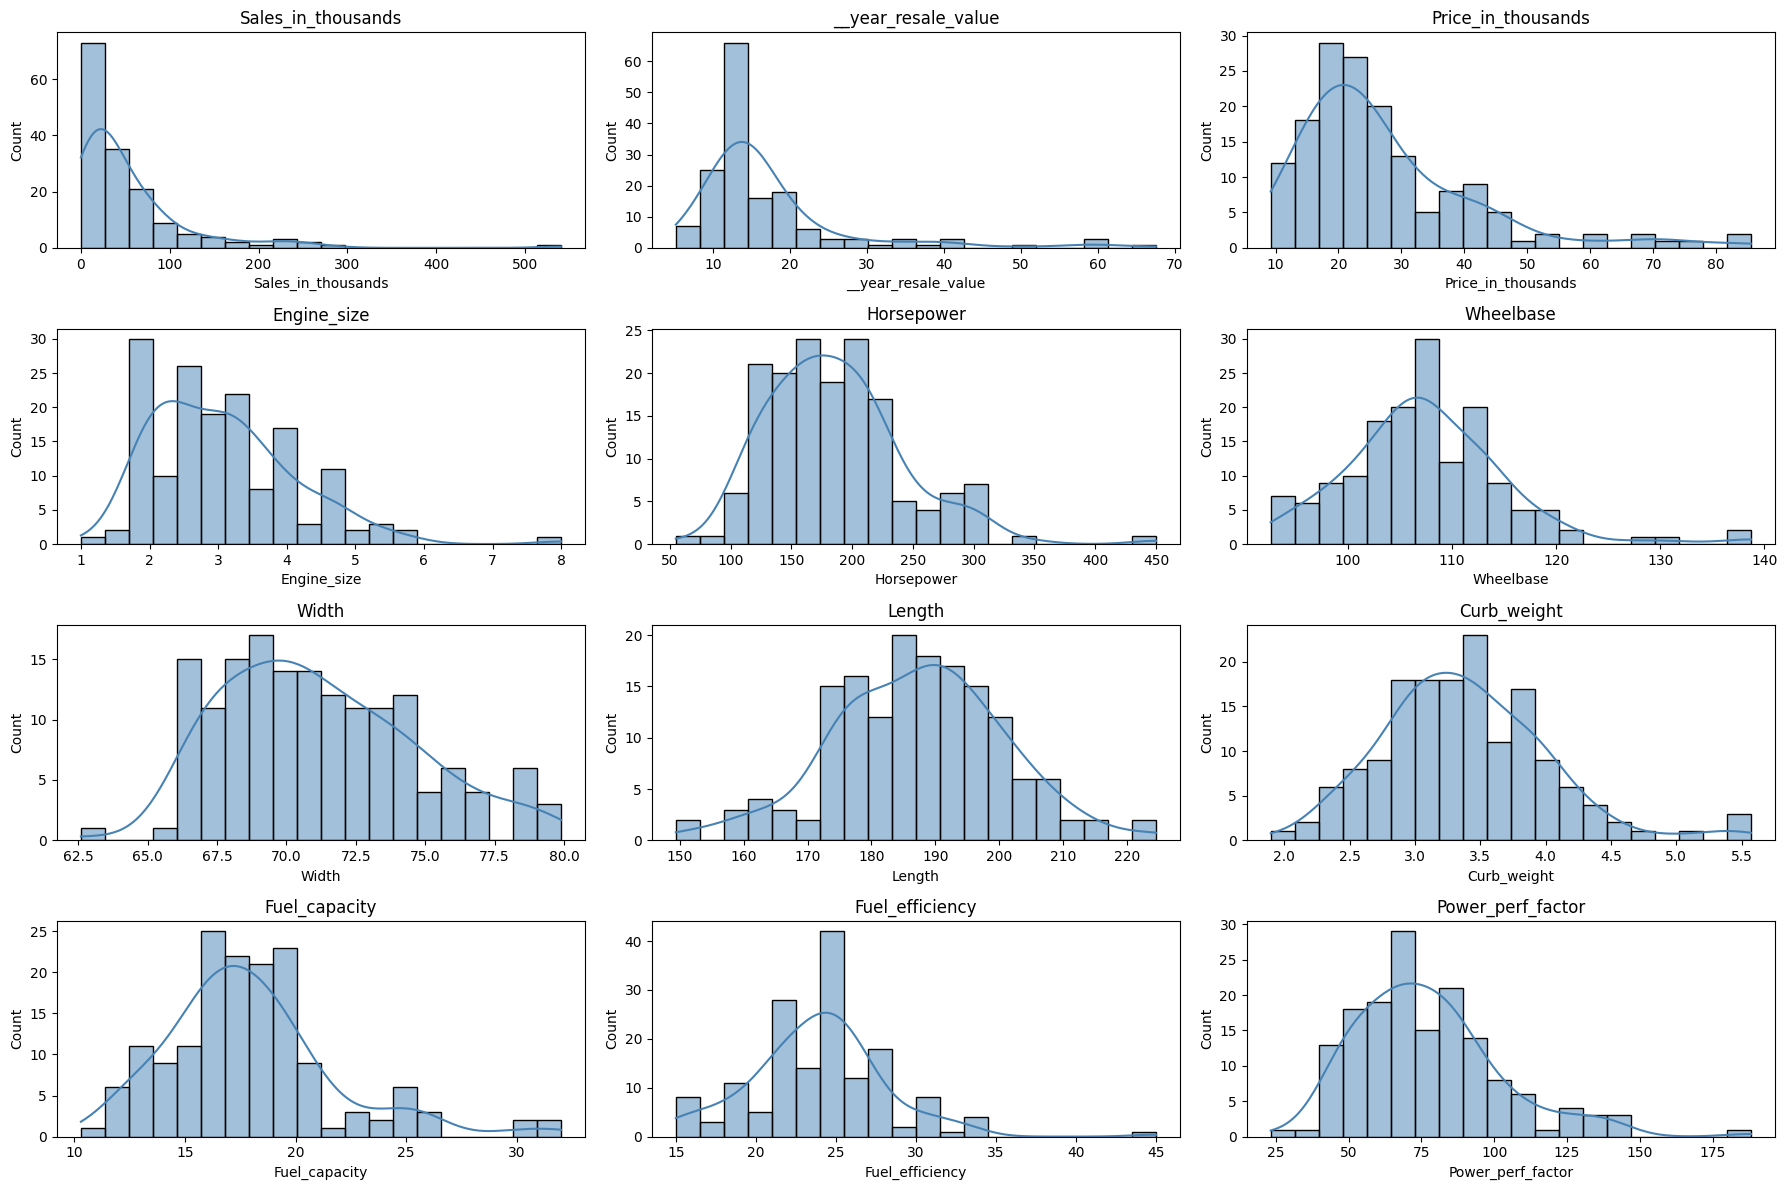

In [ ]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number")

fig, axes = plt.subplots(4, 3, figsize=(18, 12))
# The axes.flatten() method converts the 2D array of subplot axes into a 1D array. 
# This makes it easier to iterate through all subplots using a single loop and assign plots to each axis.
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, bins=20, kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

#### Distribution Observations

- Most features show a fairly normal distribution.
- `Sales_in_thousands` is highly right-skewed, meaning a few vehicle models have much higher sales than most others.
- `__year_resale_value` is slightly right-skewed, indicating that a few vehicles retain a significantly higher resale value than most others.
- `Price_in_thousands` and `Power_perf_factor` are also right-skewed due to some premium and high-performance vehicles.
- Vehicle size-related features (`Wheelbase`, `Width`, `Length`, and `Curb_weight`) appear more evenly distributed.
- Potential outliers are visible in sales, price, engine, horsepower, and performance-related features.


### 3.Outlier Detection

Outliers are observations that lie far from the majority of the data.

In the automotive industry, extreme values may represent premium vehicles, sports cars, or exceptionally popular models rather than data errors. Therefore, outliers should be investigated before deciding whether to remove them.
Boxplots provide an effective way to visualize potential outliers in numerical features.

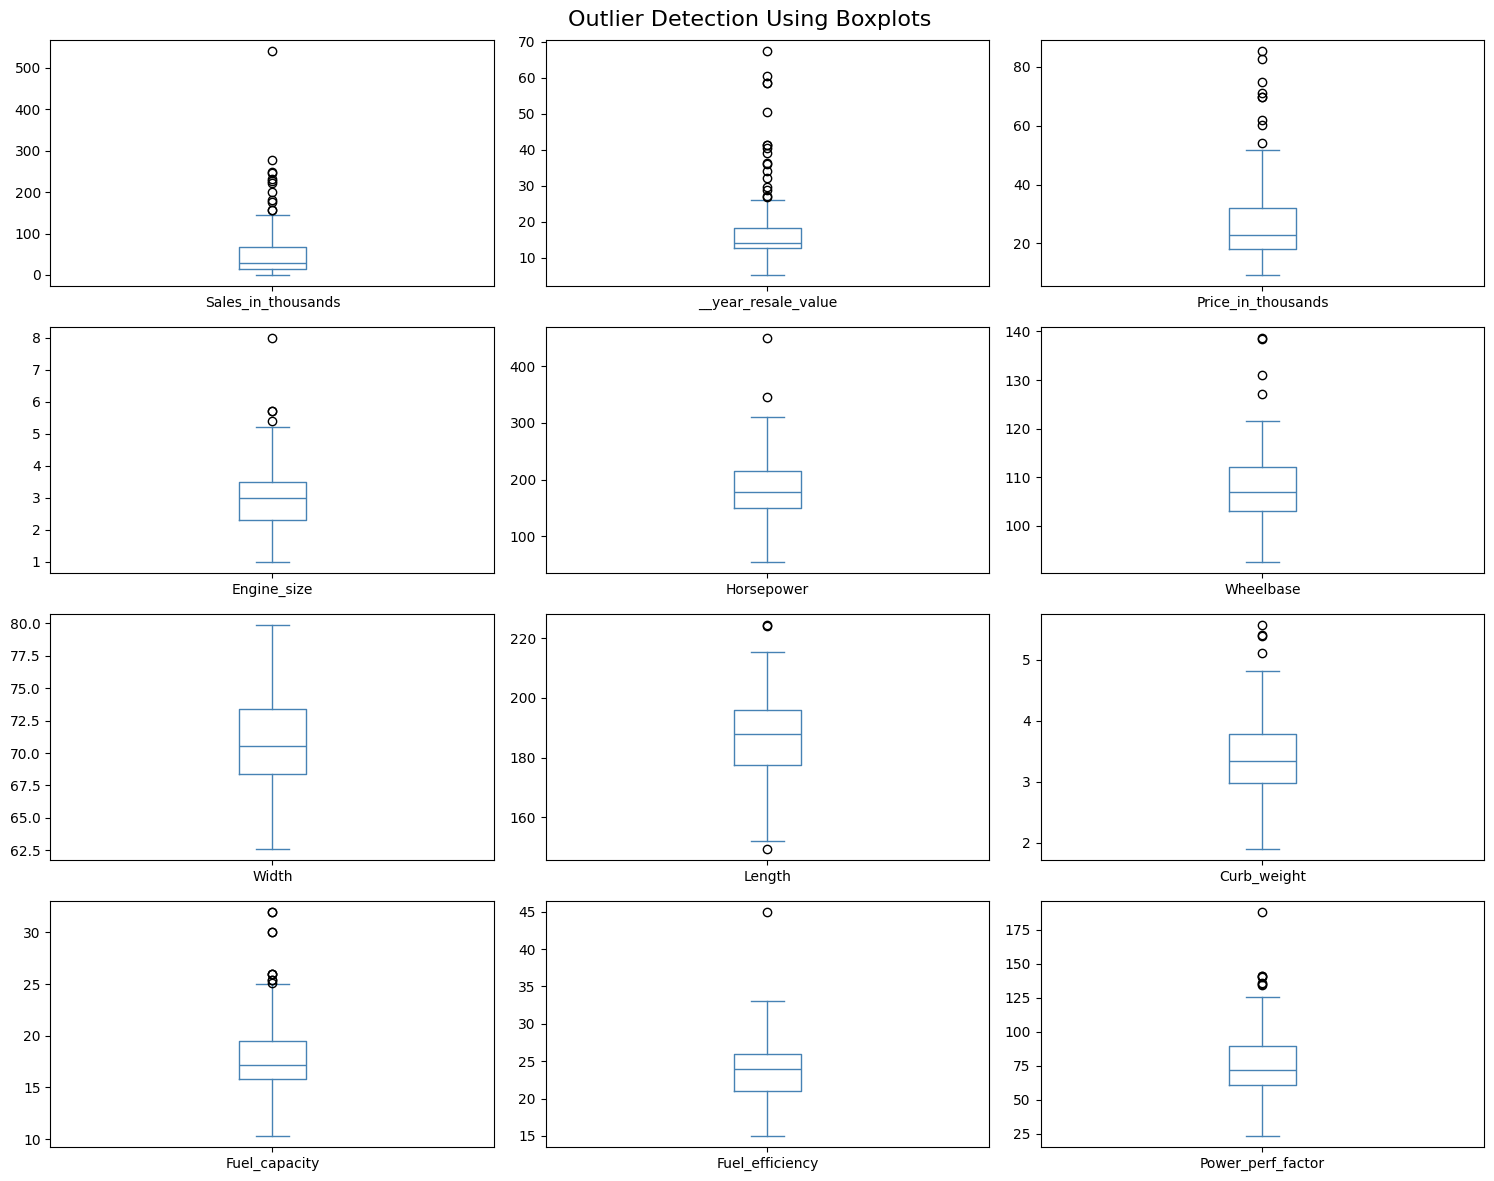

In [4]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number")

# Create vertical boxplots for all numerical features

numeric_cols.plot(kind="box", subplots=True, layout=(4, 3), figsize=(15, 12), sharex=False, sharey=False,color="steelblue")
plt.suptitle("Outlier Detection Using Boxplots", fontsize=16)
plt.tight_layout()
plt.show()

#### Outlier Observations

- Several numerical features contain potential outliers.
- The most noticeable outliers are present in `Sales_in_thousands`, `__year_resale_value`, `Price_in_thousands`, `Horsepower`, and `Power_perf_factor`.
- Features such as Width, Length, and Curb_weight show relatively few outliers and are more consistently distributed.
- These values likely represent premium, high-performance, or exceptionally popular vehicle models rather than data-entry errors.

                  Sales_in_thousands → Some cars genuinely sell much more than others.

                  Price_in_thousands → Luxury vehicles naturally have higher prices.

                  Horsepower → Sports cars can have much higher horsepower.

                  __year_resale_value → Certain brands retain value better than others.

                  Power_perf_factor → High-performance vehicles are expected to stand out.

- Therefore, the outliers will be retained for further analysis.

### 4.Categorical Feature Analysis

The dataset contains categorical features that describe vehicle manufacturers, models, and vehicle types.

In this section, we analyze:

- The distribution of vehicle types
- The number of models offered by each manufacturer

,Unique Values
Manufacturer,30
Model,156
Vehicle_type,2


Vehicle_type
Passenger    116
Car           41
Name: count, dtype: int64

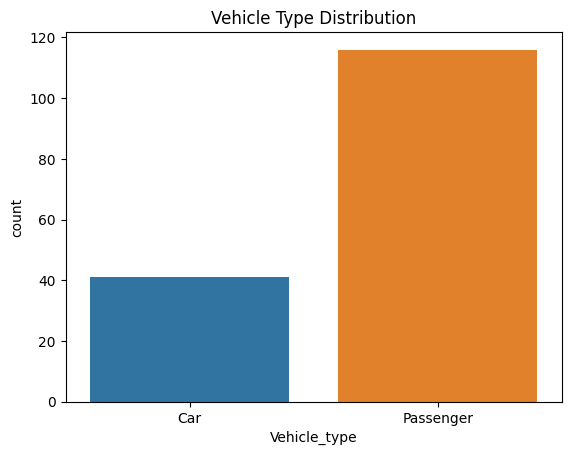

In [17]:
# Categorical feature summary

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]

cat_summary = pd.DataFrame({
    "Unique Values": df[cat_cols].nunique()
})

display(cat_summary)

# Vehicle Type Distribution

vehicle_counts = df["Vehicle_type"].value_counts()
display(vehicle_counts)

sns.countplot(data=df, x="Vehicle_type", hue="Vehicle_type", legend=False)
plt.title("Vehicle Type Distribution")
plt.show()

#### Vehicle Distribution Observations

- Passenger vehicles represent the majority of the dataset.
- Cars make up a smaller portion of the available vehicle models.

Manufacturer
Ford          11
Dodge         11
Chevrolet      9
Mercedes-B     9
Toyota         9
Chrysler       7
Mitsubishi     7
Nissan         7
Mercury        6
Oldsmobile     6
Name: count, dtype: int64

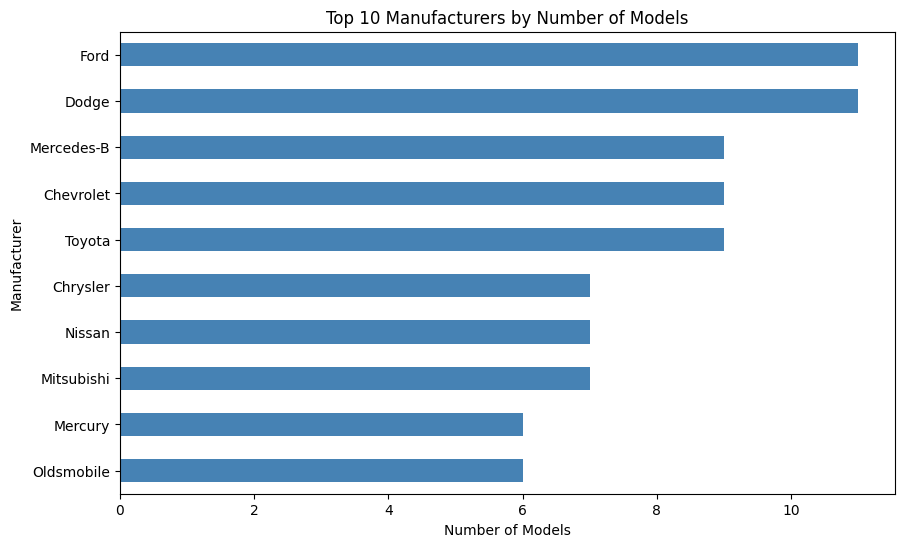

In [18]:
# Top manufacturers by number of models

manufacturer_counts = df["Manufacturer"].value_counts().head(10)
display(manufacturer_counts)

plt.figure(figsize=(10, 6))
manufacturer_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Manufacturers by Number of Models")
plt.xlabel("Number of Models")
plt.ylabel("Manufacturer")
plt.show()

#### Manufacturer Observations

- Ford and Dodge have the highest number of vehicle models in the dataset, with 11 models each.
- Chevrolet, Toyota, Mercedes-Benz, and Cadillac also have a strong presence, offering a wide range of vehicle models.
- The difference in the number of models across manufacturers is relatively small, indicating a fairly balanced representation among major automotive brands.

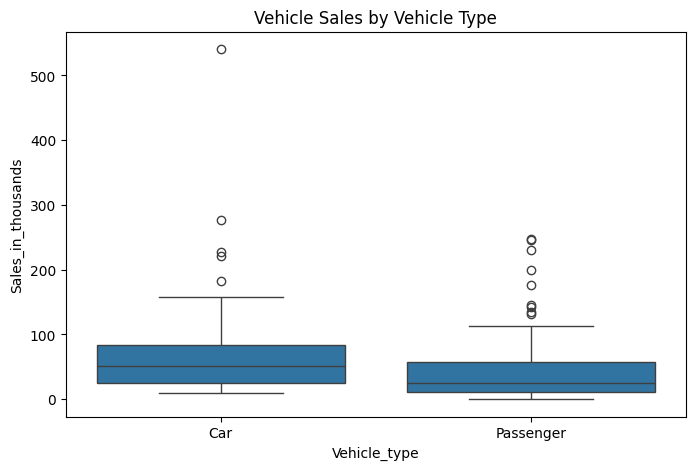

In [19]:
# Sales Performance by Vehicle Type
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Vehicle_type", y="Sales_in_thousands")
plt.title("Vehicle Sales by Vehicle Type")
plt.show()

#### Sales by Vehicle Type Observations

- Cars have a higher median sales volume compared to Passenger vehicles, indicating that car models generally achieve stronger sales performance.
- Both vehicle types contain several high-selling outliers, suggesting that a few models significantly outperform others in the market.

### 5. Relationship Analysis

To identify the factors that influence vehicle sales, we examine the relationship between the target variable (`Sales_in_thousands`) and key vehicle characteristics.

The goal is to determine whether features such as price, horsepower, engine size, fuel efficiency, and resale value are associated with higher or lower sales performance.

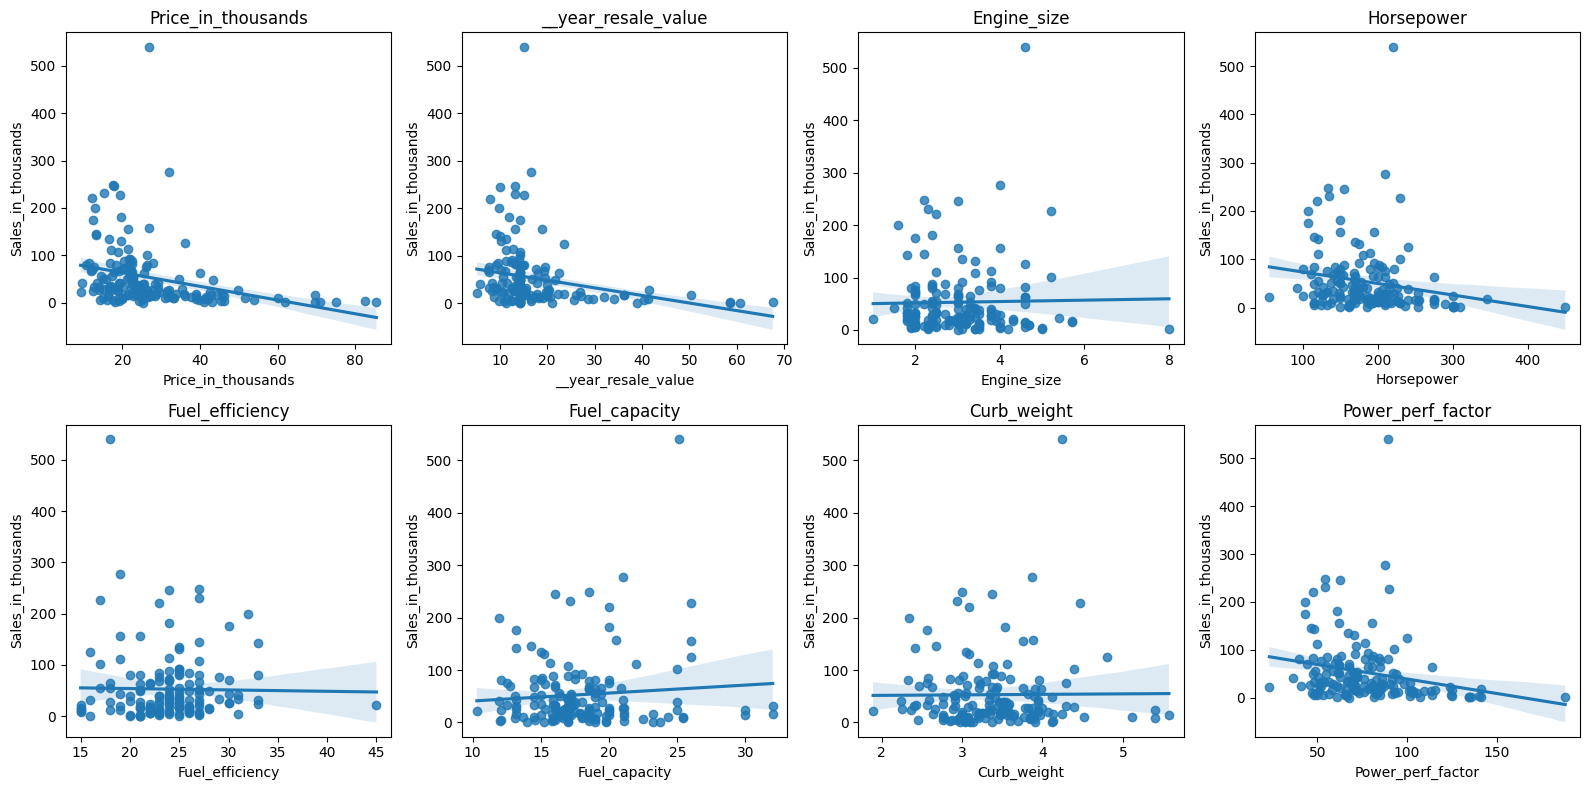

In [20]:
# Key numerical features vs Sales
features = [
    "Price_in_thousands",
    "__year_resale_value",
    "Engine_size",
    "Horsepower",
    "Fuel_efficiency",
    "Fuel_capacity",
    "Curb_weight",
    "Power_perf_factor"
]

plt.figure(figsize=(16, 8))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 4, i)
    sns.regplot(data=df, x=feature, y="Sales_in_thousands")
    plt.title(feature)
plt.tight_layout()
plt.show()

#### Relationship Analysis Observations

- `Price_in_thousands`, `Horsepower`, and `Power_perf_factor` show a weak negative relationship with sales, suggesting that higher-priced and high-performance vehicles tend to have lower sales volumes.
- `Fuel_efficiency` shows a slight positive relationship with sales, indicating that fuel-efficient vehicles may be more popular among customers.
- `Engine_size`, `Fuel_capacity`, and `Curb_weight` show very weak relationships with sales, suggesting they are not strong individual predictors of sales performance.
- `__year_resale_value` appears to have a slight positive relationship with sales, indicating that vehicles with higher resale value may attract more buyers.
- Overall, no single feature strongly explains sales performance, suggesting that vehicle sales are influenced by a combination of factors rather than one characteristic alone.

#### Correlation Analysis

Correlation analysis helps measure the strength and direction of the relationship between numerical features.A correlation heatmap provides an overview of how variables interact with each other and helps identify the features most closely associated with vehicle sales.

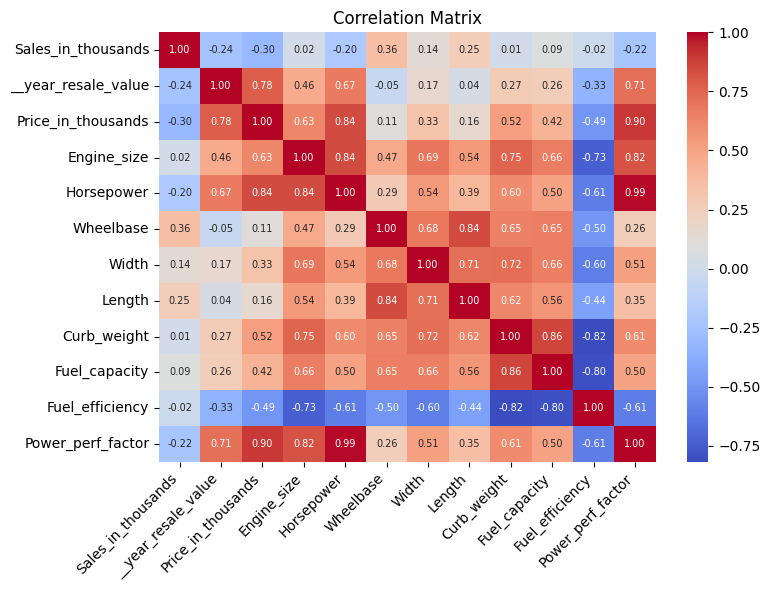

In [24]:

corr_matrix = df.select_dtypes(include="number").corr()
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

#### Correlation Analysis Observations

- `Wheelbase` shows the strongest positive correlation with sales (**0.36**), followed by `Length` (**0.25**).
- `Price_in_thousands` has the strongest negative correlation with sales (**-0.30**), suggesting that more expensive vehicles tend to sell less.
- `Horsepower` (**-0.20**) and `Power_perf_factor` (**-0.22**) also show a weak negative relationship with sales.
- Overall, no numerical feature has a strong correlation with sales, indicating that vehicle sales are influenced by multiple factors rather than a single characteristic.

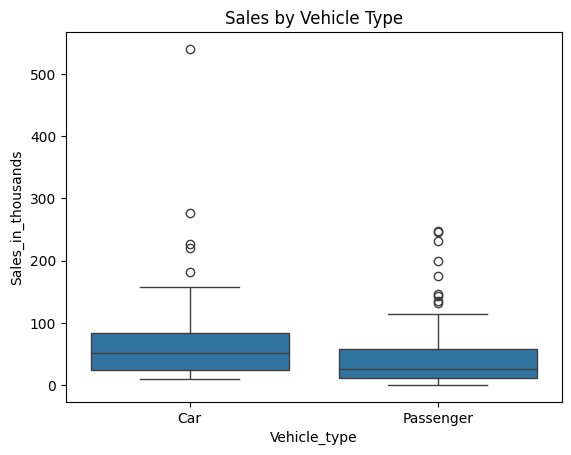

In [22]:
sns.boxplot(
    data=df,
    x="Vehicle_type",
    y="Sales_in_thousands"
)

plt.title("Sales by Vehicle Type")
plt.show()

## Key Drivers of Sales

- Among the categorical features, `Vehicle_type` appears to influence sales, with Cars showing higher median sales than Passenger vehicles.
- Among the numerical features, `Price_in_thousands` shows the strongest relationship with sales, indicating that lower-priced vehicles generally achieve higher sales volumes.


# Key Findings from EDA

- Vehicle sales are highly skewed, with a few models achieving significantly higher sales than the majority.
- Passenger vehicles make up most of the dataset, while Cars show slightly higher median sales.
- Higher-priced and high-performance vehicles generally tend to have lower sales volumes.
- Fuel-efficient vehicles show slightly better sales performance.
- No numerical feature has a strong correlation with sales, suggesting that vehicle sales are influenced by multiple factors rather than a single characteristic.
- Several outliers were identified, but they appear to represent valid business observations and were retained for analysis.